In [1]:
import pandas as pd

def load_clean_profile(path):
    # Load without header so we don't treat first row as column names
    df = pd.read_csv(path, header=None)
    
    # Rename columns
    df.columns = ["time_hours", "GW"]
    
    # Ensure numeric
    df["time_hours"] = pd.to_numeric(df["time_hours"], errors="coerce")
    df["GW"] = pd.to_numeric(df["GW"], errors="coerce")
    
    # Drop NaNs if any
    df = df.dropna()
    
    return df

watson_df = load_clean_profile(r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\Validation\Watson_HD.csv")
sansom_df = load_clean_profile(r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\Validation\Sansom_HD.csv")

watson_df.head(), sansom_df.head()


(   time_hours         GW
 0    0.573477  76.461039
 1    0.774194  77.922078
 2    0.917563  78.896104
 3    1.261649  78.896104
 4    1.376344  80.357143,
    time_hours         GW
 0    0.516129  13.149351
 1    0.745520  12.175325
 2    1.204301  11.688312
 3    0.974910  11.201299
 4    1.605735  12.175325)

In [2]:
import numpy as np
import pandas as pd

def to_halfhour(df):
    # Raw digitised data
    df = df.copy()
    df.columns = ["time_hours", "GW"]
    
    # Drop duplicates and sort
    df = df.drop_duplicates(subset="time_hours").sort_values("time_hours")
    
    # Create desired half-hour spacing: 0.0, 0.5, ..., 23.5
    target_times = np.arange(0, 24, 0.5)
    
    # Interpolate at exactly those points
    GW_interp = np.interp(target_times, df["time_hours"], df["GW"])
    
    return pd.Series(GW_interp, index=target_times)


watson_halfhour = to_halfhour(watson_df)
sansom_halfhour = to_halfhour(sansom_df)

print(len(watson_halfhour), len(sansom_halfhour))
print(watson_halfhour.head())



48 48
0.0    76.461039
0.5    76.461039
1.0    78.896104
1.5    80.823864
2.0    82.305195
dtype: float64


In [4]:
import matplotlib.pyplot as plt
# from HD_Plots import (
#     plot_peak_day_profiles_from_scenarios,
#     plot_winter_daily_heat_from_scenarios,
#     plot_week_profile_from_scenarios,
# )
from gbheatmodel.HD_Plots import *

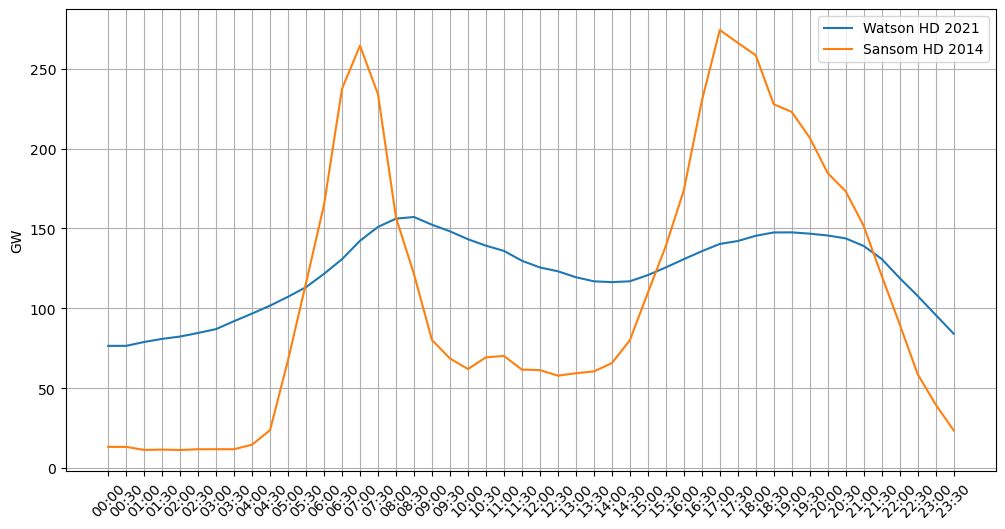

In [5]:

time_labels = [f"{int(i/2):02d}:{'30' if i % 2 else '00'}" for i in range(48)]


plt.figure(figsize=(12,6))
plt.plot(time_labels, watson_halfhour, label="Watson HD 2021")
plt.plot(time_labels, sansom_halfhour, label="Sansom HD 2014")
plt.xticks(rotation=45)
plt.ylabel("GW")
plt.grid(True)
plt.legend()
plt.show()


In [6]:
import os
from glob import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def national_half_hourly_heat_from_folder(folder_path):
    """
    Read all grid CSVs in a folder (one scenario),
    sum them to get NATIONAL half-hourly heat demand (kWh).

    Returns
    -------
    hh : pd.Series
        DatetimeIndex, national total heat demand per half-hour (kWh).
    """
    csv_files = glob(os.path.join(folder_path, "*.csv"))
    if not csv_files:
        raise ValueError(f"No CSV files found in folder: {folder_path}")

    national_df = None

    for file in csv_files:
        df = pd.read_csv(file, index_col=0, parse_dates=True)
        df = df.apply(pd.to_numeric, errors="coerce")

        if national_df is None:
            national_df = df
        else:
            national_df = national_df.add(df, fill_value=0)

    if not isinstance(national_df.index, pd.DatetimeIndex):
        raise ValueError("Index is not DatetimeIndex – check CSV format.")

    hh = national_df.sum(axis=1)  # kWh per half-hour (sum across techs)
    return hh


In [7]:
base = r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\outputs\heating_profiles"

scenario_folders = {
    "LW": fr"{base}\2010_2022_LW_2050",
    "CT": fr"{base}\2010_2022_CT_2050",
    "ST": fr"{base}\2010_2022_ST_2050",
    "FS": fr"{base}\2010_2022_FS_2050",
}

In [10]:
def plot_peak_day_profiles_with_benchmarks(scenario_folders,
                                           watson_halfhour,
                                           sansom_halfhour):
    """
    Plots:
      • Peak day (max national heat demand) for each scenario (GW)
      • Watson 2021 heat demand profile (GW)
      • Sansom 2014 heat demand profile (GW)
    """

    peak_info = {}

    # X-axis: 0, 0.5, ..., 23.5 hours
    time_axis = [round(i * 0.5, 1) for i in range(48)]

    plt.figure(figsize=(12, 6))

    # ---- GBHeatModel SCENARIO PEAK DAYS ----
    for scen, folder in scenario_folders.items():
        try:
            hh = national_half_hourly_heat_from_folder(folder)  # kWh
        except Exception as e:
            print(f"⚠️ Skipping scenario '{scen}' ({folder}): {e}")
            continue

        # Daily totals → peak day
        daily = hh.resample("D").sum()
        peak_day = daily.idxmax()

        # Extract 48 half-hours
        mask = hh.index.date == peak_day.date()
        day_series = hh[mask]

        if len(day_series) != 48:
            print(f"⚠️ Scenario '{scen}' peak day {peak_day.date()} has {len(day_series)} points.")
            continue

        # --- Convert GBHeatModel from kWh/30 min → GW ---
        # kWh per 0.5h  →  GW
        day_gw = day_series.values / (1e6 * 0.5)   # or / 500_000


        peak_info[scen] = {"date": peak_day, "profile": day_gw}

        plt.plot(time_axis, day_gw,
                 label=f"GBHeatModel {scen} ",
                 linewidth=2)

    # ---- BENCHMARKS (already GW) ----
    watson_vals = watson_halfhour.values if hasattr(watson_halfhour, "values") else watson_halfhour
    sansom_vals = sansom_halfhour.values if hasattr(sansom_halfhour, "values") else sansom_halfhour

    plt.plot(time_axis, watson_vals, label="HD_Watson et al 2021", linewidth=3, linestyle="--")
    plt.plot(time_axis, sansom_vals, label="HD_Sansom et all 2014", linewidth=3, linestyle="--")

    # --- Formatting ---
    plt.xlabel("Hour of Day")
    plt.ylabel("Heat Demand (GW)")
    plt.title("Peak-Day National Heat Demand(2050): GBHeatModel vs Watson vs Sansom")
    plt.xticks(time_axis[::2], rotation=45)  # show every full hour
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return peak_info


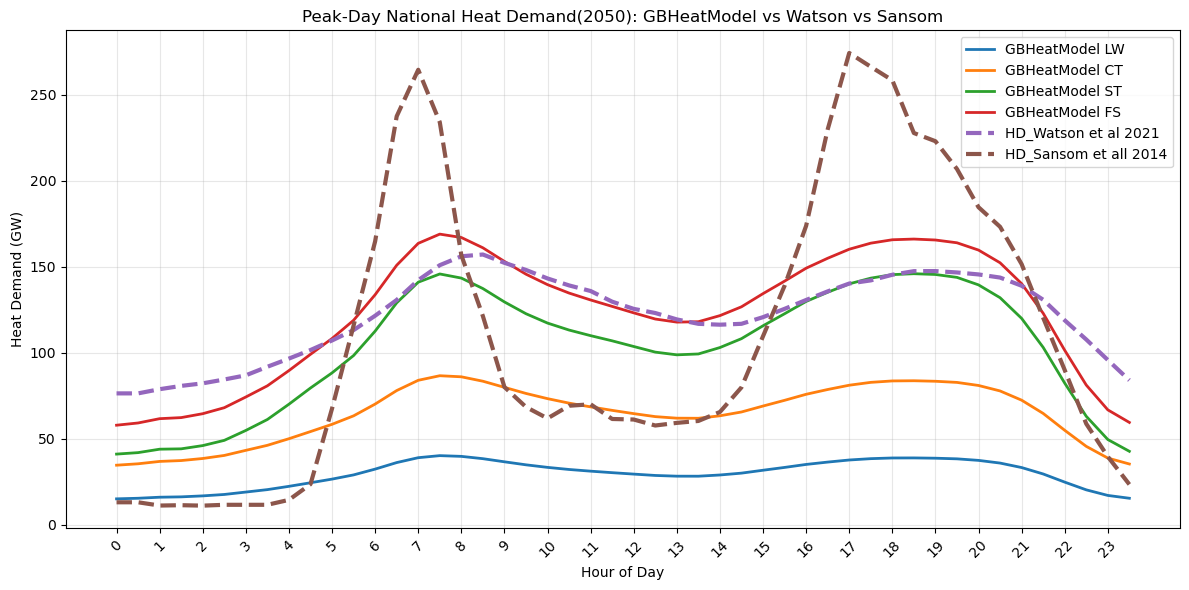

In [12]:
peak_info = plot_peak_day_profiles_with_benchmarks(
    scenario_folders,
    watson_halfhour,
    sansom_halfhour,
)



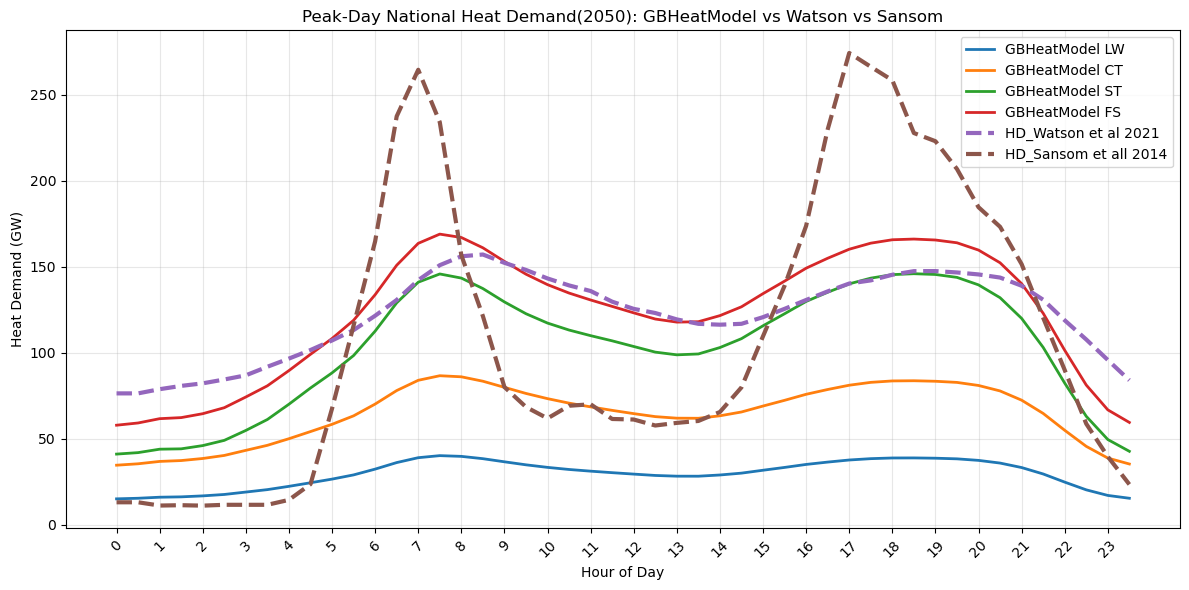

In [14]:
peak_info = plot_peak_day_profiles_with_benchmarks(
    scenario_folders,
    watson_halfhour,
    sansom_halfhour,
)


In [16]:
def plot_peak_day_profiles_from_scenarios(scenario_folders):
    """
    Plot the peak national heat-demand day for each scenario.

    Parameters
    ----------
    scenario_folders : dict
        Example:
        {
            "LW": path_to_LW,
            "CT": path_to_CT,
            "ST": path_to_ST,
        }

    Returns
    -------
    dict
        Peak day information for each scenario.
    """

    peak_info = {}

    # X-axis: 0, 0.5, ..., 23.5 hours
    time_axis = [round(i * 0.5, 1) for i in range(48)]

    plt.figure(figsize=(12, 6))

    for scen, folder in scenario_folders.items():

        try:
            hh = national_half_hourly_heat_from_folder(folder)  # kWh
        except Exception as e:
            print(f"⚠️ Skipping scenario '{scen}' ({folder}): {e}")
            continue

        # Daily totals
        daily = hh.resample("D").sum()

        # Peak day
        peak_day = daily.idxmax()

        # Extract 48 half-hour periods
        mask = hh.index.date == peak_day.date()
        day_series = hh[mask]

        if len(day_series) != 48:
            print(
                f"⚠️ Scenario '{scen}' peak day {peak_day.date()} "
                f"has {len(day_series)} points."
            )
            continue

        # Convert kWh/30min → GW
        day_gw = day_series.values / (1e6 * 0.5)

        peak_info[scen] = {
            "date": peak_day,
            "profile": day_gw,
            "peak_gw": day_gw.max(),
        }

        plt.plot(
            time_axis,
            day_gw,
            linewidth=2,
            label=f"{scen} ({peak_day.date()})",
        )

    plt.xlabel("Hour of Day")
    plt.ylabel("Heat Demand (GW)")
    plt.title("Peak-Day National Heat Demand Profiles")
    plt.xticks(time_axis[::2], rotation=45)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return peak_info

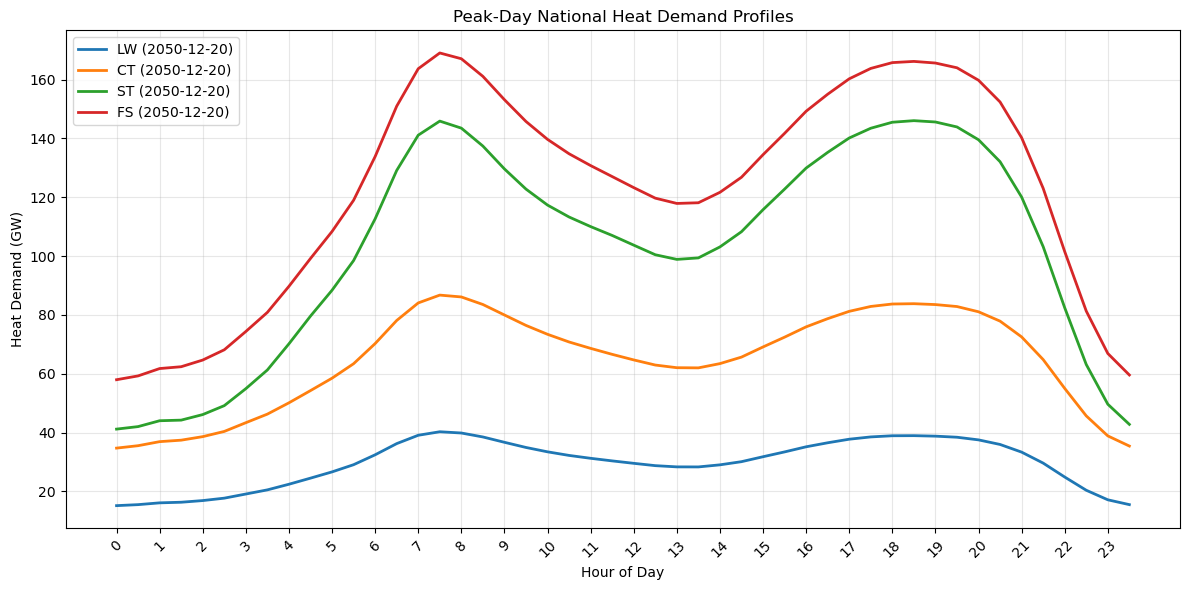

In [18]:
base = r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\outputs\heating_profiles"

scenario_folders = {
    "LW": fr"{base}\2010_2022_LW_2050",
    "CT": fr"{base}\2010_2022_CT_2050",
    "ST": fr"{base}\2010_2022_ST_2050",
    "FS": fr"{base}\2010_2022_FS_2050",
}

peak_info = plot_peak_day_profiles_from_scenarios(scenario_folders)

In [19]:
# Comparing GBHeatModel  to Watson 2021 under custom LW scenario(NO buildings efficiency improvements, change the dweelling to 25.8 million as Watson did in 2021)

In [20]:
import pandas as pd

def load_clean_profile(path):
    # Load without header so we don't treat first row as column names
    df = pd.read_csv(path, header=None)
    
    # Rename columns
    df.columns = ["time_hours", "GW"]
    
    # Ensure numeric
    df["time_hours"] = pd.to_numeric(df["time_hours"], errors="coerce")
    df["GW"] = pd.to_numeric(df["GW"], errors="coerce")
    
    # Drop NaNs if any
    df = df.dropna()
    
    return df

watson_df = load_clean_profile(r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\Validation\Watson_HD.csv")
sansom_df = load_clean_profile(r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\Validation\Sansom_HD.csv")

watson_df.head(), sansom_df.head()

(   time_hours         GW
 0    0.573477  76.461039
 1    0.774194  77.922078
 2    0.917563  78.896104
 3    1.261649  78.896104
 4    1.376344  80.357143,
    time_hours         GW
 0    0.516129  13.149351
 1    0.745520  12.175325
 2    1.204301  11.688312
 3    0.974910  11.201299
 4    1.605735  12.175325)

In [21]:
import numpy as np
import pandas as pd

def to_halfhour(df):
    # Raw digitised data
    df = df.copy()
    df.columns = ["time_hours", "GW"]
    
    # Drop duplicates and sort
    df = df.drop_duplicates(subset="time_hours").sort_values("time_hours")
    
    # Create desired half-hour spacing: 0.0, 0.5, ..., 23.5
    target_times = np.arange(0, 24, 0.5)
    
    # Interpolate at exactly those points
    GW_interp = np.interp(target_times, df["time_hours"], df["GW"])
    
    return pd.Series(GW_interp, index=target_times)


watson_halfhour = to_halfhour(watson_df)
sansom_halfhour = to_halfhour(sansom_df)

print(len(watson_halfhour), len(sansom_halfhour))
print(watson_halfhour.head())

48 48
0.0    76.461039
0.5    76.461039
1.0    78.896104
1.5    80.823864
2.0    82.305195
dtype: float64


In [23]:
import os
from glob import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def national_half_hourly_heat_from_folder(folder_path):
    """
    Read all grid CSVs in a folder (one scenario),
    sum them to get NATIONAL half-hourly heat demand (kWh).

    Returns
    -------
    hh : pd.Series
        DatetimeIndex, national total heat demand per half-hour (kWh).
    """
    csv_files = glob(os.path.join(folder_path, "*.csv"))
    if not csv_files:
        raise ValueError(f"No CSV files found in folder: {folder_path}")

    national_df = None

    for file in csv_files:
        df = pd.read_csv(file, index_col=0, parse_dates=True)
        df = df.apply(pd.to_numeric, errors="coerce")

        if national_df is None:
            national_df = df
        else:
            national_df = national_df.add(df, fill_value=0)

    if not isinstance(national_df.index, pd.DatetimeIndex):
        raise ValueError("Index is not DatetimeIndex – check CSV format.")

    hh = national_df.sum(axis=1)  # kWh per half-hour (sum across techs)
    return hh


In [24]:
base= r"C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\outputs\heating_profiles"

scenario_folder_custom = {
    "LW": fr"{base}\heating_profiles_custom",
    # "CT": fr"{base}\2010_2022_CT_2050",
    # "ST": fr"{base}\2010_2022_ST_2050",
    # "FS": fr"{base}\2010_2022_FS_2050",
}

In [27]:
def plot_peak_day_profiles_with_benchmarks(scenario_folder_custom,
                                           watson_halfhour):
                                        #    sansom_halfhour):
    """
    Plots:
      • Peak day (max national heat demand) for each scenario (GW)
      • Watson 2021 heat demand profile (GW)
      • Sansom 2014 heat demand profile (GW)
    """

    peak_info = {}

    # X-axis: 0, 0.5, ..., 23.5 hours
    time_axis = [round(i * 0.5, 1) for i in range(48)]

    plt.figure(figsize=(12, 6))

    # ---- GBHeatModel SCENARIO PEAK DAYS ----
    for scen, folder in scenario_folder_custom.items():
        try:
            hh = national_half_hourly_heat_from_folder(folder)  # kWh
        except Exception as e:
            print(f"⚠️ Skipping scenario '{scen}' ({folder}): {e}")
            continue

        # Daily totals → peak day
        daily = hh.resample("D").sum()
        peak_day = daily.idxmax()

        # Extract 48 half-hours
        mask = hh.index.date == peak_day.date()
        day_series = hh[mask]

        if len(day_series) != 48:
            print(f"⚠️ Scenario '{scen}' peak day {peak_day.date()} has {len(day_series)} points.")
            continue

        # --- Convert GBHeatModel from kWh/30 min → GW ---
        # kWh per 0.5h  →  GW
        day_gw = day_series.values / (1e6 * 0.5)   # or / 500_000


        peak_info[scen] = {"date": peak_day, "profile": day_gw}

        plt.plot(time_axis, day_gw,
                 label=f"GBHeatModel {scen}_Custom ",
                 linewidth=2)

    # ---- BENCHMARKS (already GW) ----
    watson_vals = watson_halfhour.values if hasattr(watson_halfhour, "values") else watson_halfhour
    sansom_vals = sansom_halfhour.values if hasattr(sansom_halfhour, "values") else sansom_halfhour

    plt.plot(time_axis, watson_vals, label="HD_Watson et al 2021", linewidth=3, linestyle="--")
    # plt.plot(time_axis, sansom_vals, label="HD_Sansom et all 2014", linewidth=3, linestyle="--")

    # --- Formatting ---
    plt.xlabel("Hour of Day")
    plt.ylabel("Heat Demand (GW)")
    plt.title("Peak-Day National Heat Demand(2050): GBHeatModel_Watson_Custom_Scenario")
    plt.xticks(time_axis[::2], rotation=45)  # show every full hour
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return peak_info


⚠️ Skipping scenario 'LW' (C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\outputs\heating_profiles\heating_profiles_custom): No CSV files found in folder: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\outputs\heating_profiles\heating_profiles_custom


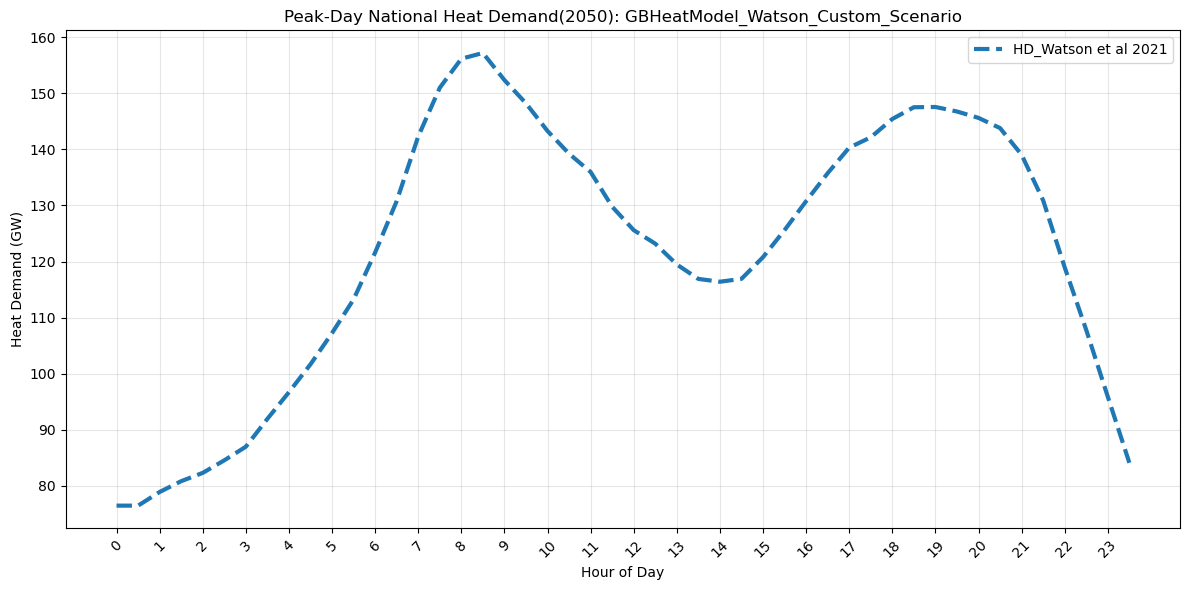

In [28]:
peak_info = plot_peak_day_profiles_with_benchmarks(
    scenario_folder_custom,
    watson_halfhour,
    # sansom_halfhour,
)